# 1-2 확률 시뮬레이터

**오늘의 질문:** 가동률 99%인 서버 5대가 모두 살아 있어야 돌아가는 서비스, 전체 가동률은 몇 %일까?

셀을 위에서부터 하나씩 실행한다 (Shift+Enter). 결과가 나오면 채팅에 적은 예측과 비교해 보자.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(0)  # 난수 생성기. 0은 씨앗(seed): 씨앗이 같으면 매번 같은 난수가 나온다

## 1. 서버 한 대를 1분마다 확인하기

'가동률 99%'를 흉내 내 보자. 1분마다 0~1 사이 난수를 하나 뽑아서, 0.99보다 작으면 그 1분은 '살아 있음'으로 친다.
0부터 1까지의 자에서 0.99보다 작은 부분이 길이의 99%니까, 난수가 거기 떨어질 확률이 99%다.

In [3]:
minutes = 10
alive = rng.random(minutes) < 0.99  # 0~1 난수가 0.99보다 작으면 True(살아 있음)
print(alive)
print('살아 있던 비율:', alive.mean())  # True는 1, False는 0으로 세서 평균을 내면 비율이 된다

[ True  True  True  True  True  True  True  True  True  True]
살아 있던 비율: 1.0


10분만 보고 이 서버가 99%짜리인지 알 수 있을까? 오래 지켜보면 어떻게 될까?

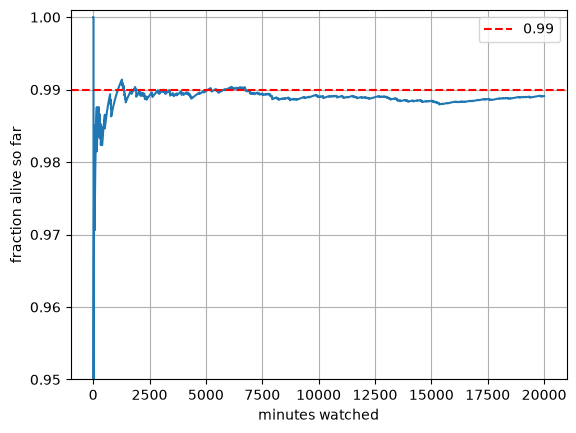

20000분 동안 살아 있던 비율: 0.9891


In [4]:
minutes = 20_000
alive = rng.random(minutes) < 0.99
# np.cumsum: 누적 합. [1, 1, 0, 1] → [1, 2, 2, 3]
fraction_so_far = np.cumsum(alive) / np.arange(1, minutes + 1)  # n분째까지 살아 있던 비율

plt.plot(fraction_so_far)
plt.axhline(0.99, color='red', linestyle='--', label='0.99')
plt.ylim(0.95, 1.001)
plt.xlabel('minutes watched')
plt.ylabel('fraction alive so far')
plt.legend()
plt.grid(True)
plt.show()
print('20000분 동안 살아 있던 비율:', fraction_so_far[-1])

아주 많이 반복할수록 비율이 한 값에 가까워진다. 그 값을 **확률**이라고 하고, 반복할수록 그 값에 가까워지는 현상을 **큰 수의 법칙**이라고 한다.

## 2. 서버 5대 — 모두 살아 있어야 서비스가 돌아간다

이번엔 1분마다 서버 5대를 한꺼번에 확인한다. 한 대라도 죽어 있으면 그 1분은 서비스가 멈춘 것이다.

In [5]:
servers = 5
minutes = 100_000
alive = rng.random((minutes, servers)) < 0.99  # 행 = 1분, 열 = 서버 한 대
print(alive[:3])  # 처음 3분만 보기

service_up = alive.all(axis=1)  # 행마다: 그 1분 동안 5대가 전부 살아 있었나
print('서비스 가동률:', service_up.mean())

[[ True  True  True  True  True]
 [ True  True  True  True  True]
 [ True  True  True  True  True]]
서비스 가동률: 0.9506


In [6]:
hours = 30 * 24  # 한 달 = 720시간
print(f'서버 1대: 한 달에 {(1 - 0.99) * hours:.1f}시간 멈춤')
print(f'서비스:   한 달에 {(1 - service_up.mean()) * hours:.1f}시간 멈춤')

서버 1대: 한 달에 7.2시간 멈춤
서비스:   한 달에 35.6시간 멈춤


## 3. 서버가 더 많으면?

서버를 1대부터 100대까지 늘려 가며 같은 실험을 한다. 모든 서버의 가동률은 99%다.

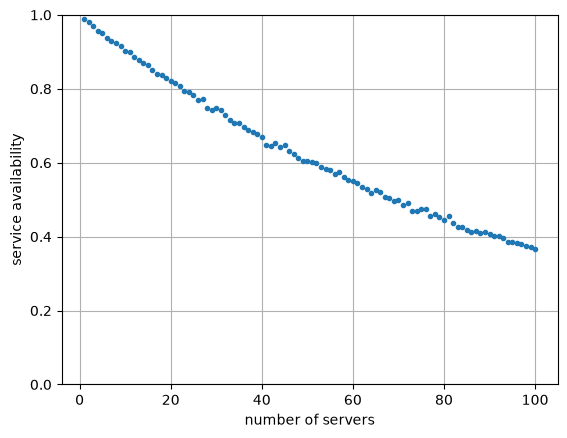

서버 10대: 0.9019
서버 100대: 0.3673


In [7]:
counts = np.arange(1, 101)  # 서버 1대 ~ 100대
availability = []
for n in counts:
    alive = rng.random((10_000, n)) < 0.99
    availability.append(alive.all(axis=1).mean())

plt.plot(counts, availability, '.')
plt.ylim(0, 1)
plt.xlabel('number of servers')
plt.ylabel('service availability')
plt.grid(True)
plt.show()
print('서버 10대:', availability[9])
print('서버 100대:', availability[99])

## 4. 서버들이 전원 하나를 같이 쓴다면?

지금까지는 서버마다 따로따로 고장 났다. 이번엔 서버 5대가 전원 하나를 같이 쓰고, 고장은 전부 이 전원 때문에 난다고 하자. 서버 한 대만 보면 여전히 99%다.

In [8]:
minutes = 100_000
power_ok = rng.random(minutes) < 0.99  # 1분마다 전원이 살아 있나
alive = np.column_stack([power_ok] * servers)  # 서버 5대가 전원과 같이 살고 같이 죽는다

print('서버 1대 가동률:', alive[:, 0].mean())
print('서비스 가동률:', alive.all(axis=1).mean())

서버 1대 가동률: 0.9898
서비스 가동률: 0.9898


똑같이 99%짜리 서버 5대인데 2번과 결과가 다르다. 무엇이 달라졌을까? 이론 시간에 이 차이를 **독립**이라는 말로 정확하게 정의한다.